In [4]:
pip install tensorflow matplotlib

Note: you may need to restart the kernel to use updated packages.


In [7]:
import tensorflow as tf
from tensorflow import keras 
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np

In [8]:
data = np.load('mnist_dataset.npz')
print(data.files)

['X_train', 'y_train', 'X_test', 'y_test']


In [9]:
with np.load('mnist_dataset.npz') as data:
    x_train, y_train = data['X_train'], data['y_train']
    x_test, y_test = data['X_test'], data['y_test']


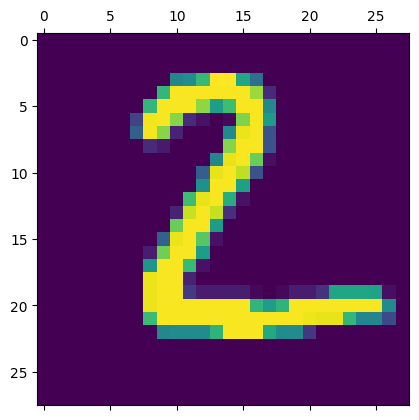

In [10]:
plt.matshow(x_test[1])

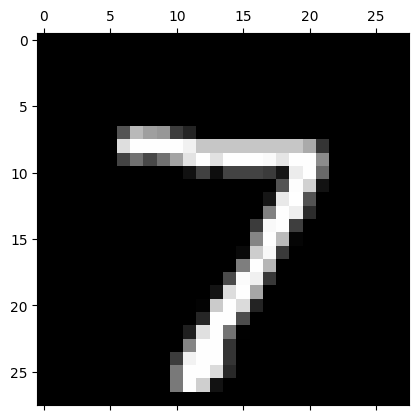

In [12]:
plt.matshow(x_test[0],cmap ="gray")

In [13]:
x_train = x_train/255
x_terst = x_test/255

In [18]:
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28,28)),
    keras.layers.Dense(128,activation = "relu"),
    keras.layers.Dense(10,activation = "softmax")
    ])

In [19]:
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)                  │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
model.compile(optimizer="sgd",loss="sparse_categorical_crossentropy",metrics=["accuracy"])

In [27]:
history = model.fit(x_train,y_train,validation_data=(x_test,y_test),epochs=10)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9549 - loss: 0.1617 - val_accuracy: 0.9488 - val_loss: 22.9332
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9577 - loss: 0.1532 - val_accuracy: 0.9534 - val_loss: 21.2134
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9596 - loss: 0.1455 - val_accuracy: 0.9553 - val_loss: 20.0036
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9617 - loss: 0.1383 - val_accuracy: 0.9558 - val_loss: 20.0447
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9633 - loss: 0.1320 - val_accuracy: 0.9577 - val_loss: 19.0255
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9654 - loss: 0.1264 - val_accuracy: 0.9603 - val_loss: 18.1404
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9667 - loss: 0.1209 - val_accuracy: 0.9611 - val_loss: 17.3846
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9683 - loss: 0.

In [28]:
test_loss,test_acc = model.evaluate(x_test,y_test)
print("loss=%.3f"%test_loss)
print("acc=%.3f"%test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9642 - loss: 16.9675
loss=16.968
acc=0.964


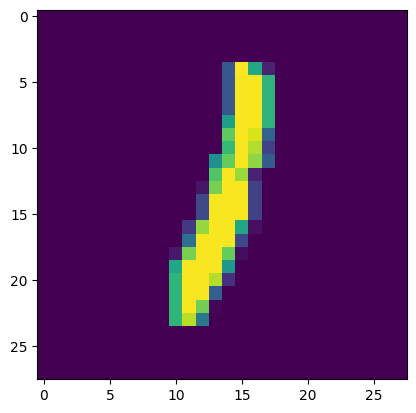

In [29]:
import random
n = random.randint(0,9999)
plt.imshow(x_test[n])
plt.show()

In [30]:
predicted_value = model.predict(x_test)
print(predicted_value[n])

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
[0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]


In [31]:
print(np.argmax(predicted_value[n]))

1


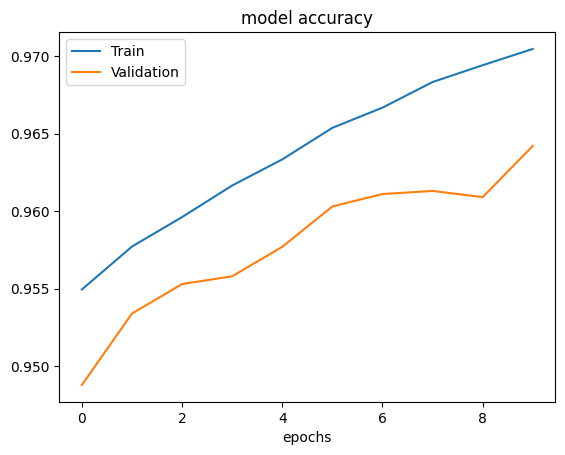

In [33]:
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.title("model accuracy")
plt.xlabel("accuracy")
plt.xlabel("epochs")
plt.legend(["Train","Validation"],loc = "upper left")
plt.show()

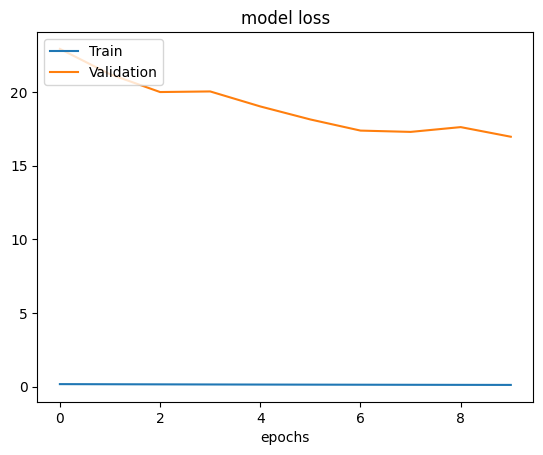

In [37]:
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])
plt.title("model loss")
plt.xlabel("loss")
plt.xlabel("epochs")
plt.legend(["Train","Validation"],loc = "upper left")
plt.show()

In [36]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])